# 04. YOLO26s: выбранные варианты

Сравнение `baseline` и `adamw_nbs16` на `data` и `data_real`.
Разметка `2026-10-15-clear`: частица с различимым телом, включая окантовку; пыль и неясные скопления исключены.
Класс — `particle`. Обучение из `yolo26s.pt`.


In [3]:
from pathlib import Path
from errno import EACCES, EINVAL
from time import sleep
import gc
import math

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer
import yaml

ROOT = Path.cwd().resolve()
if ROOT.name == 'research':
    ROOT = ROOT.parent

DATASETS = {'real': ROOT / 'data_real', 'mixed': ROOT / 'data'}
MODELS = ROOT / 'models'
COMPARISON = MODELS / 'comparison_clear.csv'
CHECKPOINT = ROOT / 'research/yolo26s.pt'
ANNOTATION_VERSION = '2026-10-15-clear'

EPOCHS = 50
PATIENCE = 20
IMAGE_SIZE = 1024
EVAL_IMAGE_SIZE = 1024
BATCH_SIZE = 4
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
SEED = 42
CONFIDENCE = 0.25
MAX_DETECTIONS = 1000

## 1. Данные

Train — D03/D04, val — D01/D02, test — D05.
Все увеличения одной группы остаются в одной выборке. Синтетика — только в train набора `mixed`.


In [4]:
plans_by_dataset = {}
configs = {}
for dataset, data in DATASETS.items():
    config = data / 'dataset.yaml'
    config.write_text(yaml.safe_dump({
        'path': data.as_posix(), 'train': 'images/train',
        'val': 'images/val', 'test': 'images/test', 'names': {0: 'particle'},
    }, sort_keys=False), encoding='utf-8')
    configs[dataset] = config
    plans = []
    for split in ('train', 'val', 'test'):
        for image in sorted((data / 'images' / split).glob('*.png')):
            label = data / 'labels' / split / f'{image.stem}.txt'
            plans.append({'image': image, 'label': label, 'split': split,
                          'objects': len(label.read_text(encoding='utf-8').splitlines())})
    plans_by_dataset[dataset] = plans

inventory = pd.concat([
    pd.DataFrame(plans).assign(dataset=dataset)
    for dataset, plans in plans_by_dataset.items()
], ignore_index=True)
display(inventory.groupby(['dataset', 'split']).agg(
    images=('image', 'count'), objects=('objects', 'sum')))

images  objects
dataset split                 
mixed   test        3      101
        train      36     1072
        val         4      223
real    test        3      101
        train      24      943
        val         4      223

## 2. Параметры

| Вариант | Параметры |
|---|---|
| baseline | `optimizer=auto`, `nbs=64` |
| adamw_nbs16 | `optimizer=AdamW`, `lr0=0.0003`, `momentum=0.9`, `warmup_bias_lr=0`, `nbs=16` |

Варианты выбраны по предыдущей серии; её метрики относятся к прежней разметке.
Остальные настройки одинаковы. Число шагов зависит от размера train.


In [5]:
TRAIN_ARGS = dict(
    epochs=EPOCHS, patience=PATIENCE, imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE, device=DEVICE, workers=0, seed=SEED,
    deterministic=True, optimizer='auto', pretrained=True,
    project=str(MODELS), exist_ok=False, save=True, plots=False,
    cache=False, val=True, max_det=MAX_DETECTIONS,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=10.0, translate=0.05,
    scale=0.15, fliplr=0.5, flipud=0.5, mosaic=0.0, mixup=0.0, close_mosaic=0,
)
EXPERIMENTS = {
    'baseline': {},
    'adamw_nbs16': dict(optimizer='AdamW', lr0=0.0003,
                      momentum=0.9, warmup_bias_lr=0.0, nbs=16),
}
ACTIVE_EXPERIMENTS = list(EXPERIMENTS)
print('Устройство:', DEVICE)
display(pd.DataFrame([
    {'experiment': name, 'optimizer': 'auto', 'nbs': 64, **EXPERIMENTS[name]}
    for name in ACTIVE_EXPERIMENTS
]).set_index('experiment').fillna('auto'))

Устройство: 0


,optimizer,nbs,lr0,momentum,warmup_bias_lr
experiment,,,,,
baseline,auto,64,auto,auto,auto
adamw_nbs16,AdamW,16,0.0003,0.9,0.0


## 3. Обучение

Веса и история четырёх запусков — `models/clear_<набор>_<вариант>/`.
Сводка — `models/comparison_clear.csv`.
AP оценивается при `conf=0.001`, подсчёт — при `conf=0.25`.
Precision и recall берутся из отчёта Ultralytics; их порог может отличаться от порога подсчёта.


In [6]:
# Повтор сохранения при временном сбое доступа к файлу весов.
class CheckpointTrainer(DetectionTrainer):
    def save_model(self):
        for attempt in range(5):
            try:
                return super().save_model()
            except OSError as error:
                if error.errno not in (EACCES, EINVAL) or attempt == 4:
                    raise
                sleep(0.5 * (attempt + 1))


def evaluate(detector, run_dir, split, dataset):
    config = configs[dataset]
    plans = plans_by_dataset[dataset]
    metrics = detector.val(
        data=str(config.resolve()), split=split, imgsz=EVAL_IMAGE_SIZE,
        batch=BATCH_SIZE, device=DEVICE, workers=0, conf=0.001, iou=0.7,
        max_det=MAX_DETECTIONS, rect=True, augment=False, half=False,
        plots=False, save_json=False, save_txt=False,
        project=str(run_dir.parent), name=run_dir.name, exist_ok=True,
    )
    values = {
        f'{split}_precision': float(metrics.box.mp),
        f'{split}_recall': float(metrics.box.mr),
        f'{split}_map50': float(metrics.box.map50),
        f'{split}_map50_95': float(metrics.box.map),
    }
    counts = []
    for plan in (p for p in plans if p['split'] == split):
        result = detector.predict(
            source=str(plan['image']), imgsz=EVAL_IMAGE_SIZE,
            conf=CONFIDENCE, iou=0.7, max_det=MAX_DETECTIONS, device=DEVICE,
            rect=True, augment=False, half=False, save=False, save_txt=False, verbose=False,
        )[0]
        predicted = len(result.boxes)
        counts.append({'image': plan['image'].stem, 'labels': plan['objects'],
                       'predicted': predicted, 'absolute_error': abs(predicted - plan['objects'])})
    counts = pd.DataFrame(counts)
    values[f'{split}_count_mae'] = float(counts['absolute_error'].mean())
    return values, counts


def save_comparison(row):
    table = pd.read_csv(COMPARISON) if COMPARISON.exists() else pd.DataFrame()
    if not table.empty:
        table = table.loc[table['run_dir'] != row['run_dir']]
    table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    table.to_csv(COMPARISON, index=False)



runs = []
for dataset in DATASETS:
    plans = plans_by_dataset[dataset]
    for name in ACTIVE_EXPERIMENTS:
        args = {**TRAIN_ARGS, **EXPERIMENTS[name],
                'data': str(configs[dataset].resolve()),
                'name': f'clear_{dataset}_{name}'}
        model = YOLO(str(CHECKPOINT), task='detect')
        model.train(trainer=CheckpointTrainer, **args)
        run_dir = Path(model.trainer.save_dir)
        best = run_dir / 'weights/best.pt'
        history = pd.read_csv(run_dir / 'results.csv')
        history.columns = history.columns.str.strip()
        row = {
            'annotation_version': ANNOTATION_VERSION,
            'dataset': dataset, 'experiment': name, 'seed': SEED,
            'train_images': sum(p['split'] == 'train' for p in plans),
            'train_imgsz': args['imgsz'], 'eval_imgsz': EVAL_IMAGE_SIZE,
            'batch': BATCH_SIZE, 'count_conf': CONFIDENCE,
            'max_det': MAX_DETECTIONS, 'epochs_limit': EPOCHS,
            'patience': PATIENCE, 'epochs_completed': len(history),
            'peak_epoch': int(history.loc[history['metrics/mAP50-95(B)'].idxmax(), 'epoch']),
            'optimizer': args['optimizer'], 'lr0': args.get('lr0', 'auto'),
            'freeze': args.get('freeze', 0), 'nbs': args.get('nbs', 64),
            'run_dir': run_dir.relative_to(ROOT).as_posix(),
            'weights': best.relative_to(ROOT).as_posix(),
        }
        del model
        gc.collect()
        torch.cuda.empty_cache()

        detector = YOLO(str(best), task='detect')
        values, counts = evaluate(detector, run_dir, 'val', dataset)
        row.update(values)
        runs.append(row)
        save_comparison(row)
        display(pd.DataFrame([row])[
            ['dataset', 'experiment', 'val_map50', 'val_map50_95', 'val_count_mae']])
        del detector
        gc.collect()
        torch.cuda.empty_cache()

New https://pypi.org/project/ultralytics/8.4.178 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga

,dataset,experiment,val_map50,val_map50_95,val_count_mae
0,real,baseline,0.793062,0.525082,21.75


New https://pypi.org/project/ultralytics/8.4.178 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMa

,dataset,experiment,val_map50,val_map50_95,val_count_mae
0,real,adamw_nbs16,0.714586,0.465293,20.25


New https://pypi.org/project/ultralytics/8.4.178 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\2026

,dataset,experiment,val_map50,val_map50_95,val_count_mae
0,mixed,baseline,0.740249,0.480463,9.75


New https://pypi.org/project/ultralytics/8.4.178 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\20

,dataset,experiment,val_map50,val_map50_95,val_count_mae
0,mixed,adamw_nbs16,0.622716,0.374006,4.5


## 4. Сравнение на val

Модель выбирается по mAP50–95. MAE подсчёта рассматривается вместе с precision и recall:
лишние и пропущенные частицы могут компенсироваться в общем количестве.


,dataset,experiment,peak_epoch,val_precision,val_recall,val_map50,val_map50_95,val_count_mae,weights
0,real,baseline,31,0.8124,0.7399,0.7931,0.5251,21.75,models/clear_real_baseline/weights/best.pt
2,mixed,baseline,24,0.6917,0.6440,0.7402,0.4805,9.75,models/clear_mixed_baseline/weights/best.pt
1,real,adamw_nbs16,30,0.6765,0.6189,0.7146,0.4653,20.25,models/clear_real_adamw_nbs16/weights/best.pt
3,mixed,adamw_nbs16,19,0.7144,0.4978,0.6227,0.3740,4.50,models/clear_mixed_adamw_nbs16/weights/best.pt


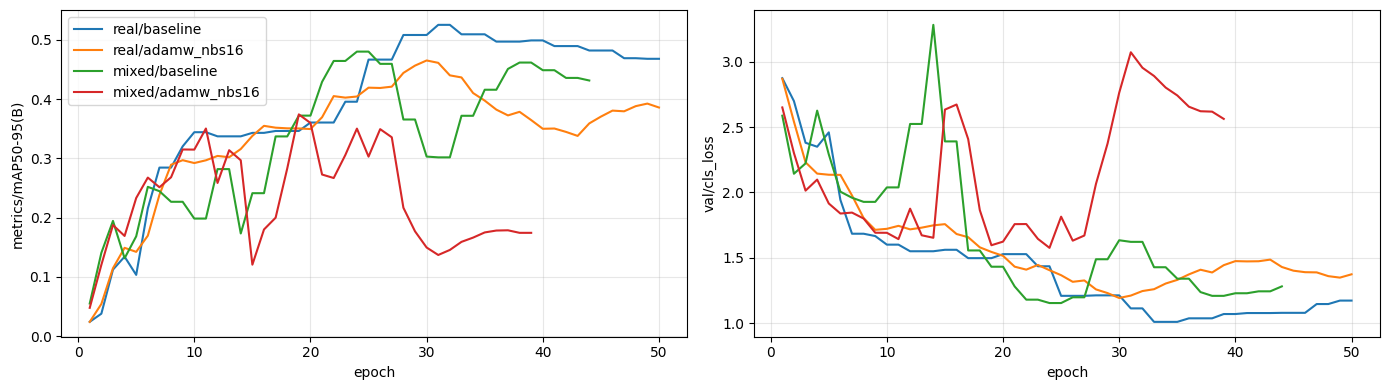

Выбор по val: real baseline | models/clear_real_baseline/weights/best.pt


In [7]:
ranking = pd.DataFrame(runs).sort_values('val_map50_95', ascending=False)
display(ranking[['dataset', 'experiment', 'peak_epoch', 'val_precision', 'val_recall',
                 'val_map50', 'val_map50_95', 'val_count_mae', 'weights']].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for run in runs:
    history = pd.read_csv(ROOT / run['run_dir'] / 'results.csv')
    history.columns = history.columns.str.strip()
    for ax, column in zip(axes, ['metrics/mAP50-95(B)', 'val/cls_loss']):
        ax.plot(history['epoch'], history[column], label=f"{run['dataset']}/{run['experiment']}")
        ax.set(xlabel='epoch', ylabel=column)
        ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

selected = ranking.iloc[0]
print('Выбор по val:', selected['dataset'], selected['experiment'], '|', selected['weights'])

## 5. Предсказания на val

Рамки выбранной модели и число размеченных частиц по кадрам.


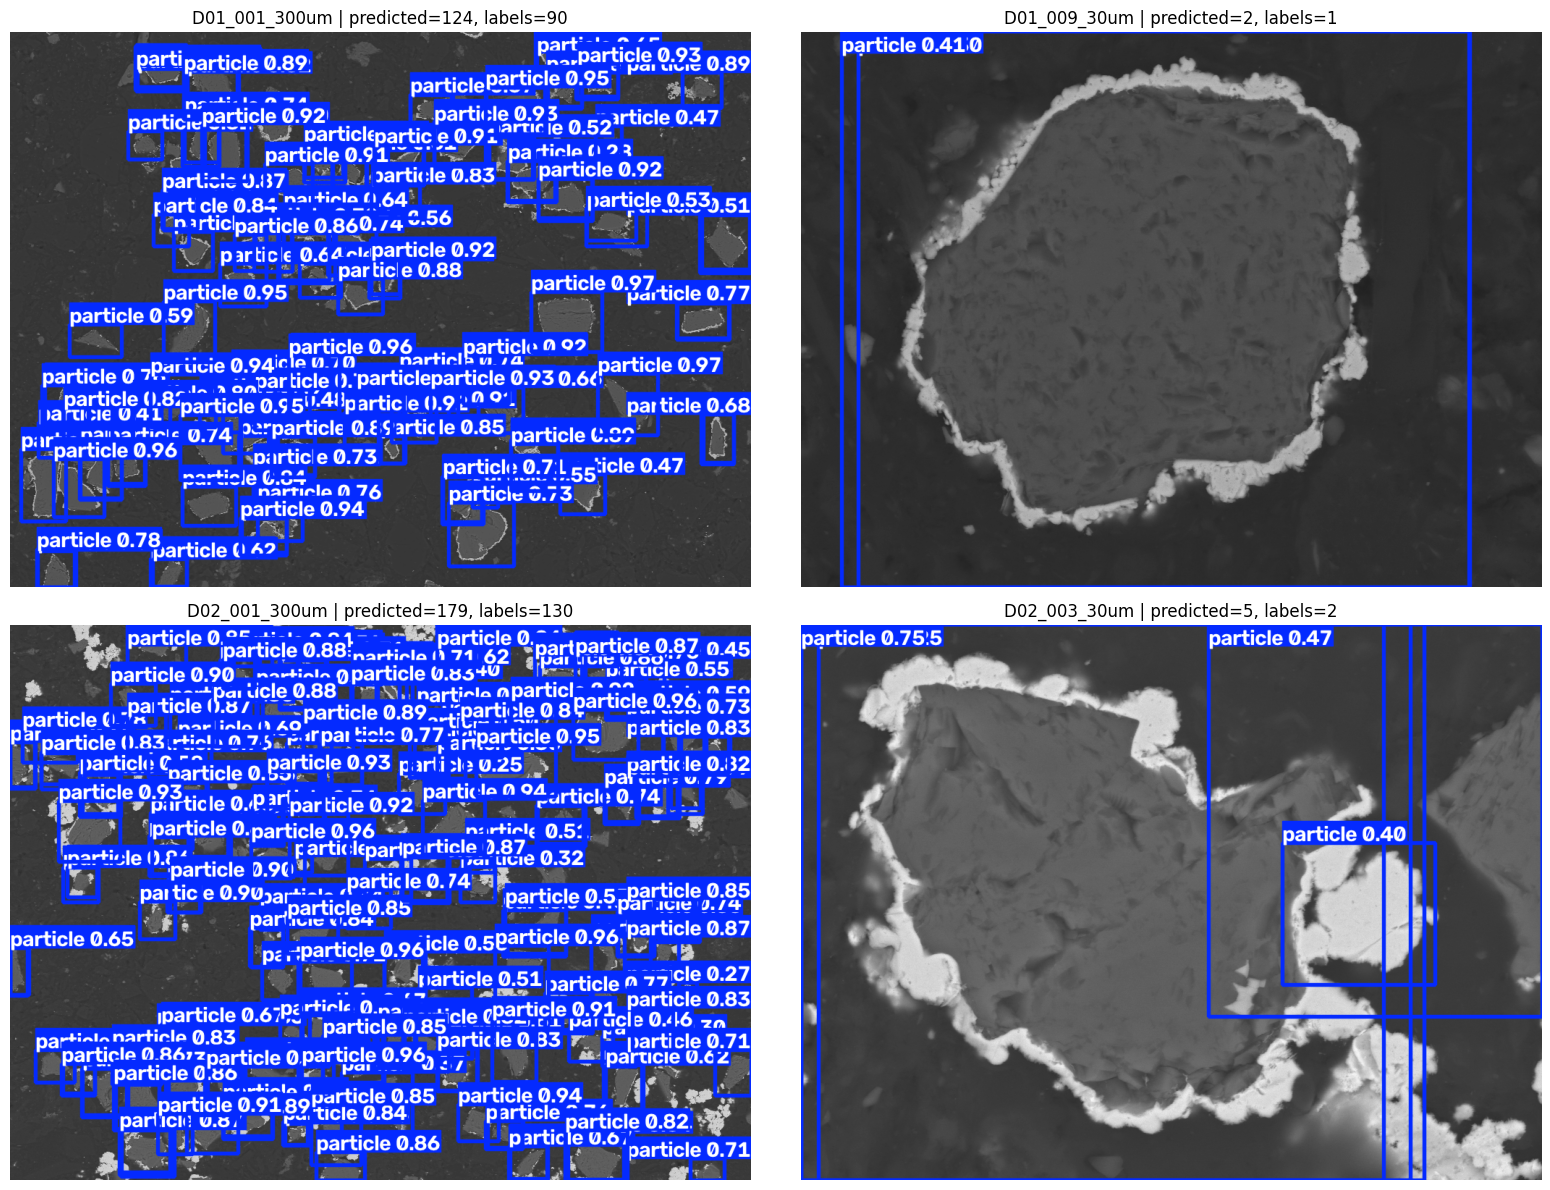

In [8]:
detector = YOLO(str(ROOT / selected['weights']), task='detect')
preview = [p for p in plans_by_dataset[selected['dataset']] if p['split'] == 'val']
fig, axes = plt.subplots(math.ceil(len(preview) / 2), 2, figsize=(16, 6 * math.ceil(len(preview) / 2)), squeeze=False)
for ax, plan in zip(axes.flat, preview):
    result = detector.predict(
        source=str(plan['image']), imgsz=EVAL_IMAGE_SIZE, conf=CONFIDENCE,
        iou=0.7, max_det=MAX_DETECTIONS, device=DEVICE, rect=True, augment=False,
        half=False, save=False, save_txt=False, verbose=False,
    )[0]
    ax.imshow(result.plot()[:, :, ::-1])
    ax.set_title(f"{plan['image'].stem} | predicted={len(result.boxes)}, labels={plan['objects']}")
    ax.axis('off')
for ax in list(axes.flat)[len(preview):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
del detector
gc.collect()
torch.cuda.empty_cache()

## 6. Проверка на test

Оценка четырёх вариантов на D05 с фиксированными параметрами.
D05 использовалась раньше; независимая проверка требует новых образцов.


In [9]:
test_counts = []
for row in runs:
    detector = YOLO(str(ROOT / row['weights']), task='detect')
    values, counts = evaluate(detector, ROOT / row['run_dir'], 'test', row['dataset'])
    row.update(values)
    save_comparison(row)
    test_counts.append(counts.assign(dataset=row['dataset'], experiment=row['experiment']))
    del detector
    gc.collect()
    torch.cuda.empty_cache()

display(pd.DataFrame(runs)[['dataset', 'experiment', 'test_precision', 'test_recall',
                           'test_map50', 'test_map50_95', 'test_count_mae']].round(4))
display(pd.concat(test_counts, ignore_index=True)[['dataset', 'experiment', 'image', 'labels', 'predicted', 'absolute_error']])

Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 1717.5539.1 MB/s, size: 1557.7 KB)
val: Scanning C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\labels\test... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 856.9it/s 0.0s
val: New cache created: C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.6it/s 0.2s
                   all          3        101      0.793      0.608      0.745      0.423
Speed: 0.3ms preprocess, 14.5ms inference, 0.0ms loss, 0.1ms postprocess per image
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5

,dataset,experiment,test_precision,test_recall,test_map50,test_map50_95,test_count_mae
0,real,baseline,0.7933,0.6080,0.7446,0.4232,12.0000
1,real,adamw_nbs16,0.7364,0.5248,0.6637,0.3845,11.6667
2,mixed,baseline,0.5812,0.4851,0.5098,0.2830,6.3333
3,mixed,adamw_nbs16,0.6833,0.5941,0.6683,0.3830,6.6667


,dataset,experiment,image,labels,predicted,absolute_error
0,real,baseline,D05_001_400um,95,126,31
1,real,baseline,D05_003_40um,5,2,3
2,real,baseline,D05_011_10um,1,3,2
3,real,adamw_nbs16,D05_001_400um,95,63,32
4,real,adamw_nbs16,D05_003_40um,5,2,3
5,real,adamw_nbs16,D05_011_10um,1,1,0
6,mixed,baseline,D05_001_400um,95,81,14
7,mixed,baseline,D05_003_40um,5,1,4
8,mixed,baseline,D05_011_10um,1,0,1
9,mixed,adamw_nbs16,D05_001_400um,95,77,18


## 7. Результаты

Сводка серии — `comparison_clear.csv`, пути к весам — столбец `weights`.
В `comparison.csv` сохранены результаты прежней разметки.


In [10]:
summary = pd.DataFrame(runs)
display(summary.sort_values('val_map50_95', ascending=False)[
    ['dataset', 'experiment', 'train_images', 'peak_epoch',
     'val_map50_95', 'test_map50_95', 'test_count_mae', 'weights']
].round(4))
display(summary.pivot(index='experiment', columns='dataset',
                      values=['val_map50_95', 'test_map50_95', 'test_count_mae']).round(4))
print('Выбрана по val:', selected['weights'])

,dataset,experiment,train_images,peak_epoch,val_map50_95,test_map50_95,test_count_mae,weights
0,real,baseline,24,31,0.5251,0.4232,12.0000,models/clear_real_baseline/weights/best.pt
2,mixed,baseline,36,24,0.4805,0.2830,6.3333,models/clear_mixed_baseline/weights/best.pt
1,real,adamw_nbs16,24,30,0.4653,0.3845,11.6667,models/clear_real_adamw_nbs16/weights/best.pt
3,mixed,adamw_nbs16,36,19,0.3740,0.3830,6.6667,models/clear_mixed_adamw_nbs16/weights/best.pt


val_map50_95         test_map50_95         test_count_mae         
dataset            mixed    real         mixed    real          mixed     real
experiment                                                                    
adamw_nbs16       0.3740  0.4653         0.383  0.3845         6.6667  11.6667
baseline          0.4805  0.5251         0.283  0.4232         6.3333  12.0000

Выбрана по val: models/clear_real_baseline/weights/best.pt
